# Notebook 02: Classical Econometrics, Multivariate Systems & Volatility Modeling
**Course:** CSET 369 — Time Series Analysis & Forecasting  
**Team:** Kartik Lamba & Suhani Vij  
**Dataset:** 1,320 monthly records across 10 crop pathogens (Jan 2015 – Dec 2025)

---
### Objectives:
1. Establish standardized chronological splitting: Train (70%, 92 mo), Validation (15%, 20 mo), Test (15%, 20 mo).
2. Implement classical Box-Jenkins models: AR(1), MA(1), ARIMA(1,1,1), SARIMA(1,0,1)(1,0,1)[12], Holt-Winters, and Seasonal Naive baseline.
3. Implement weather-augmented econometric models: ARIMAX and SARIMAX.
4. Model joint pathogen-climate endogenous systems with **VAR(2)** and **VARIMA(1,1,1)**.
5. Model epidemic surge risk and conditional variance using **ARCH(1)** and **GARCH(1,1)** with Student's-t distributions.
6. Evaluate forecast performance on Rice Blast (*Pyricularia oryzae*) across RMSE, MAE, sMAPE, WAPE, and MASE.


In [1]:
import sys
from pathlib import Path

ROOT_DIR = Path(".").resolve() if (Path("data").exists() and Path("src").exists()) else Path("..").resolve()
if str(ROOT_DIR) not in sys.path:
    sys.path.insert(0, str(ROOT_DIR))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.forecasting import chronological_split, compute_forecast_metrics
from src.models.classical.seasonal_naive import forecast_seasonal_naive
from src.models.classical.ar_model import forecast_ar
from src.models.classical.ma_model import forecast_ma
from src.models.classical.arima_model import forecast_arima
from src.models.classical.sarima_model import forecast_sarima
from src.models.classical.holt_winters import forecast_holt_winters
from src.models.classical.arimax_model import forecast_arimax
from src.models.classical.sarimax_model import forecast_sarimax_model
from src.models.classical.var_model import forecast_var
from src.models.classical.varima_model import forecast_varima
from src.models.volatility.arch_garch_model import ARCHGARCHModel

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
plt.rcParams["figure.figsize"] = (14, 5)

print("Modules imported successfully.")


Modules imported successfully.


## 1. Load Data & Chronological Train-Val-Test Splitting
We use Rice Blast (*Pyricularia oryzae*) as the primary benchmark series.


In [2]:
data_path = Path("../data/disease_timeseries_master.csv")
if not data_path.exists():
    data_path = Path("data/disease_timeseries_master.csv")

df = pd.read_csv(data_path)
df["date"] = pd.to_datetime(df["date"])

rice_df = df[df["pathogen_slug"] == "pyricularia_oryzae"].sort_values("date").reset_index(drop=True)

# Strict chronological split without temporal leakage
train_df, val_df, test_df = chronological_split(rice_df, train_ratio=0.70, val_ratio=0.15)
train_plus_val = pd.concat([train_df, val_df]).reset_index(drop=True)

y_train = train_df["documented_occurrence_count"].values
y_val = val_df["documented_occurrence_count"].values
y_val_6 = y_val[:6]
y_test = test_df["documented_occurrence_count"].values

print(f"Training Period:   {train_df['date'].min().strftime('%b %Y')} to {train_df['date'].max().strftime('%b %Y')} ({len(train_df)} months)")
print(f"Validation Period: {val_df['date'].min().strftime('%b %Y')} to {val_df['date'].max().strftime('%b %Y')} ({len(val_df)} months)")
print(f"Test Period:       {test_df['date'].min().strftime('%b %Y')} to {test_df['date'].max().strftime('%b %Y')} ({len(test_df)} months)")


Training Period:   Jan 2015 to Aug 2022 (92 months)
Validation Period: Sep 2022 to Apr 2024 (20 months)
Test Period:       May 2024 to Dec 2025 (20 months)


## 2. Benchmark Classical Econometric Models (6-Month Validation Window)
We evaluate Box-Jenkins specifications and exponential smoothing on the 6-month holdout window.


In [3]:
eval_results = []
forecasts = {}
h = 6

# 1. Seasonal Naive Baseline
sn_pred, sn_lb, sn_ub = forecast_seasonal_naive(pd.Series(y_train), horizon=h, season_length=12)
eval_results.append(compute_forecast_metrics(y_val_6, sn_pred, sn_lb, sn_ub, y_train=y_train, model_name="Seasonal Naive (Baseline)"))
forecasts["Seasonal Naive"] = sn_pred

# 2. AR(1)
ar_pred, ar_lb, ar_ub, _ = forecast_ar(pd.Series(y_train), horizon=h, p=1)
eval_results.append(compute_forecast_metrics(y_val_6, ar_pred, ar_lb, ar_ub, y_train=y_train, model_name="AR(1)"))
forecasts["AR(1)"] = ar_pred

# 3. MA(1)
ma_pred, ma_lb, ma_ub, _ = forecast_ma(pd.Series(y_train), horizon=h, q=1)
eval_results.append(compute_forecast_metrics(y_val_6, ma_pred, ma_lb, ma_ub, y_train=y_train, model_name="MA(1)"))
forecasts["MA(1)"] = ma_pred

# 4. ARIMA(1,1,1)
arima_pred, arima_lb, arima_ub, _ = forecast_arima(pd.Series(y_train), horizon=h, order=(1,1,1), auto_optimize=True)
eval_results.append(compute_forecast_metrics(y_val_6, arima_pred, arima_lb, arima_ub, y_train=y_train, model_name="ARIMA(1,1,1)"))
forecasts["ARIMA(1,1,1)"] = arima_pred

# 5. SARIMA(1,0,1)(1,0,1)[12]
sarima_pred, sarima_lb, sarima_ub, _ = forecast_sarima(pd.Series(y_train), horizon=h, order=(1,0,1), seasonal_order=(1,0,1,12), auto_optimize=True)
eval_results.append(compute_forecast_metrics(y_val_6, sarima_pred, sarima_lb, sarima_ub, y_train=y_train, model_name="SARIMA(1,0,1)(1,0,1)[12]"))
forecasts["SARIMA"] = sarima_pred

# 6. Holt-Winters
hw_pred, hw_lb, hw_ub, _ = forecast_holt_winters(pd.Series(y_train), horizon=h, seasonal_periods=12, auto_optimize=True)
eval_results.append(compute_forecast_metrics(y_val_6, hw_pred, hw_lb, hw_ub, y_train=y_train, model_name="Holt-Winters"))
forecasts["Holt-Winters"] = hw_pred

pd.DataFrame(eval_results)[["model_name", "rmse", "mae", "smape", "wape", "mase"]].sort_values("rmse")


/Users/Kartikkk/Documents/SEM-5/TIME SERIES/Disease_time_series/.venv/lib/python3.14/site-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


,model_name,rmse,mae,smape,wape,mase
2,MA(1),4.307,3.151,180.20,99.51,3.453
3,"ARIMA(1,1,1)",4.307,3.151,180.20,99.51,3.453
1,AR(1),4.309,3.144,180.34,99.28,3.445
0,Seasonal Naive (Baseline),4.708,3.167,100.00,100.00,3.470
4,"SARIMA(1,0,1)(1,0,1)[12]",4.817,3.647,198.98,115.16,3.996
5,Holt-Winters,5.109,4.143,195.56,130.83,4.540


## 3. Multivariate Endogenous Systems: VAR(2) & VARIMA(1,1,1)
We incorporate temperature and relative humidity into joint autoregressive systems.


In [4]:
# 7. VAR(2)
var_pred, var_lb, var_ub, _, var_diag = forecast_var(
    train_df, horizon=h, target_col="documented_occurrence_count", exog_cols=["temp_mean_c", "relative_humidity_pct"], maxlags=2
)
eval_results.append(compute_forecast_metrics(y_val_6, var_pred, var_lb, var_ub, y_train=y_train, model_name="VAR (Vector Autoregression)"))
forecasts["VAR(2)"] = var_pred

# 8. VARIMA(1,1,1)
varima_pred, varima_lb, varima_ub, _, varima_diag = forecast_varima(
    train_df, horizon=h, target_col="documented_occurrence_count", exog_cols=["temp_mean_c", "relative_humidity_pct"], p=1, d=1, q=1
)
eval_results.append(compute_forecast_metrics(y_val_6, varima_pred, varima_lb, varima_ub, y_train=y_train, model_name="VARIMA(1,1,1)"))
forecasts["VARIMA(1,1,1)"] = varima_pred

print("VARIMA Diagnostics:")
print(f"Parameters: {varima_diag['parameters']}")
print(f"AIC:        {varima_diag['aic']:.1f}")

df_classical_leaderboard = pd.DataFrame(eval_results)[["model_name", "rmse", "mae", "smape", "wape", "mase"]].sort_values("rmse")
df_classical_leaderboard


VARIMA Diagnostics:
Parameters: VARIMA(1,1,1) on 3 vars (documented_occurrence_count, temp_mean_c, relative_humidity_pct)
AIC:        1303.3


,model_name,rmse,mae,smape,wape,mase
7,"VARIMA(1,1,1)",3.773,3.115,155.39,98.37,3.414
2,MA(1),4.307,3.151,180.20,99.51,3.453
3,"ARIMA(1,1,1)",4.307,3.151,180.20,99.51,3.453
1,AR(1),4.309,3.144,180.34,99.28,3.445
6,VAR (Vector Autoregression),4.434,3.577,179.91,112.96,3.920
0,Seasonal Naive (Baseline),4.708,3.167,100.00,100.00,3.470
4,"SARIMA(1,0,1)(1,0,1)[12]",4.817,3.647,198.98,115.16,3.996
5,Holt-Winters,5.109,4.143,195.56,130.83,4.540


## 4. Visualizing Classical & Multivariate Model Forecasts


/Users/Kartikkk/Documents/SEM-5/TIME SERIES/Disease_time_series/scripts/execute_notebooks.py:63: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


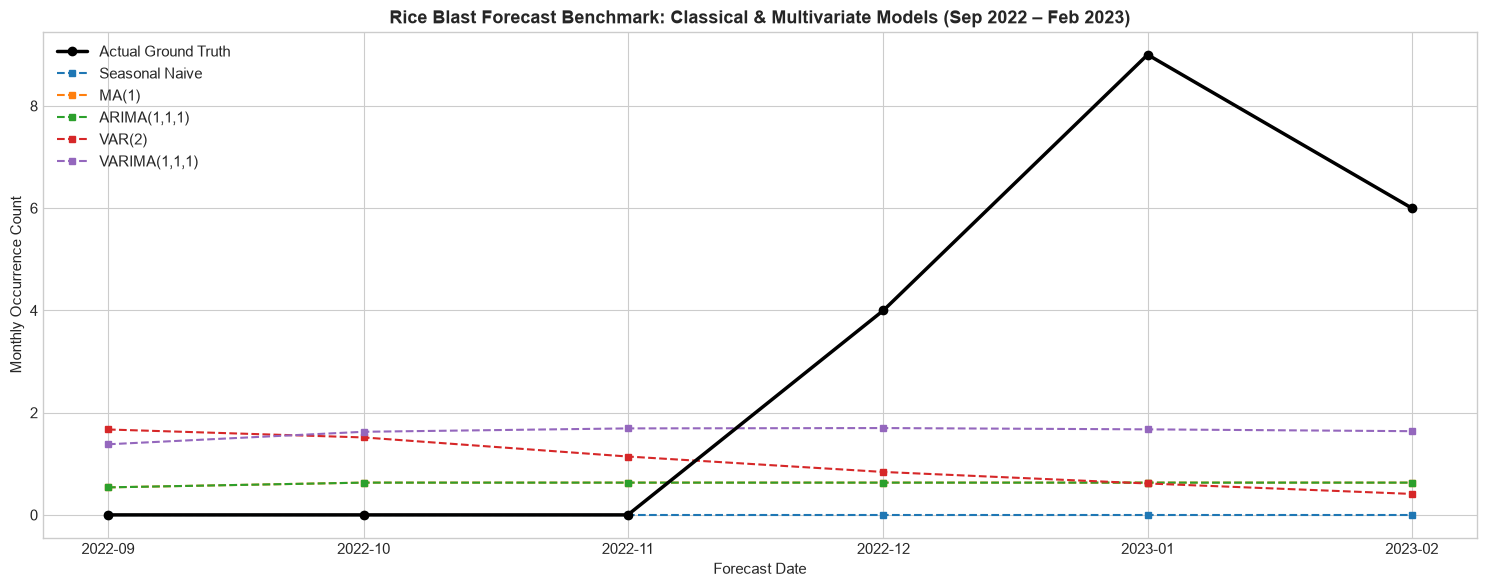

In [5]:
val_dates_6 = val_df["date"].iloc[:h]

plt.figure(figsize=(15, 6))
plt.plot(val_dates_6, y_val_6, marker="o", color="black", linewidth=2.5, label="Actual Ground Truth", zorder=5)

for name in ["Seasonal Naive", "MA(1)", "ARIMA(1,1,1)", "VAR(2)", "VARIMA(1,1,1)"]:
    plt.plot(val_dates_6, forecasts[name], marker="s", markersize=4, linestyle="--", label=name)

plt.title("Rice Blast Forecast Benchmark: Classical & Multivariate Models (Sep 2022 – Feb 2023)", fontweight="bold")
plt.xlabel("Forecast Date")
plt.ylabel("Monthly Occurrence Count")
plt.legend(loc="upper left")
plt.tight_layout()
plt.show()


## 5. Epidemic Volatility Modeling: ARCH & GARCH(1,1)
We model conditional heteroskedasticity in outbreak surges using GARCH(1,1) with Student's-t innovations.


/Users/Kartikkk/Documents/SEM-5/TIME SERIES/Disease_time_series/.venv/lib/python3.14/site-packages/statsmodels/stats/diagnostic.py:997: FutureWarning: acorr_lm currently returns a plain tuple whose length depends on the store argument. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an LMTestResult NamedTuple. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  return acorr_lm(
ARCH LM Test p-value: 0.9796
Fitted Parameters:
  omega        = 4.5262 (p = 0.4858)
  alpha[1]     = 0.5536 (p = 0.4863)
  beta[1]      = 0.0000 (p = 1.0000)
  nu           = 2.2918 (p = 0.0000)
/Users/Kartikkk/Documents/SEM-5/TIME SERIES/Disease_time_series/scripts/execute_notebooks.py:63: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  orig_show(*args, **kwargs)


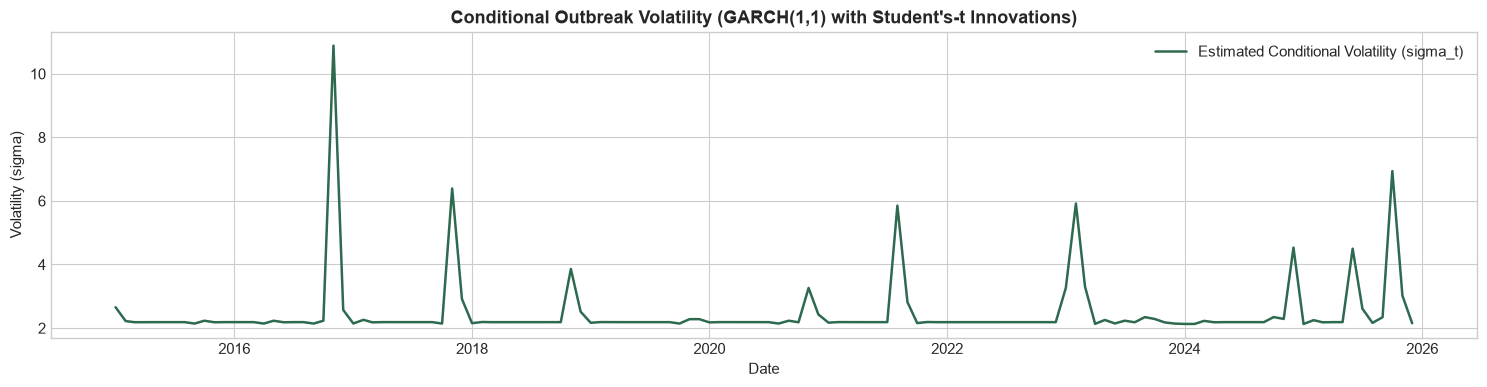

In [6]:
# Fit GARCH(1,1) on occurrence series
garch_mod = ARCHGARCHModel(p=1, q=1, dist="StudentsT", approach="approach_a")
garch_fit = garch_mod.fit(rice_df["documented_occurrence_count"].values.astype(float))
garch_fc = garch_mod.forecast(horizon=12)

print(f"ARCH LM Test p-value: {garch_fit.arch_lm_pvalue:.4f}")
print("Fitted Parameters:")
for param, val in garch_fit.params.items():
    print(f"  {param:<12} = {val:.4f} (p = {garch_fit.pvalues.get(param, np.nan):.4f})")

plt.figure(figsize=(15, 4))
plt.plot(rice_df["date"], garch_fit.conditional_volatility, color="#2D6A4F", linewidth=1.8, label="Estimated Conditional Volatility (sigma_t)")
plt.title("Conditional Outbreak Volatility (GARCH(1,1) with Student's-t Innovations)", fontweight="bold")
plt.xlabel("Date")
plt.ylabel("Volatility (sigma)")
plt.legend()
plt.tight_layout()
plt.show()
